# Math 32 — Lecture 31: Carrying Out Tests, and Two Kinds of Errors

Companion notebook for Lecture 31 (Standard 11: Hypothesis Testing). Every figure and number in the slides is made here.

**How this notebook is organized.** Every code cell is **self-contained**, so you can change a number and re-run just that cell.
Figures are saved in a `figures/` folder next to the notebook.

**Today's two examples**
1. **A mean ($t$-test):** the new coffee cart from Lecture 28 ($n = 10$ days, $\bar x = 306$, $s = 30.40$). The company claims carts average \$280/day.
2. **A proportion ($z$-test):** the coin from Lecture 29 (61 heads in 100 flips). Is it fair enough to settle a bet?

Then: **Type I** errors (probability $\alpha$) and **Type II** errors (probability $\beta$).

## 0. Three tests, one recipe

| situation | test statistic | table |
|---|---|---|
| average, $\sigma$ known | $z^* = \dfrac{\bar x - \mu_0}{\sigma/\sqrt n}$ | Table B.1 ($Z$) |
| average, $\sigma$ unknown (use $s$) | $t^* = \dfrac{\bar x - \mu_0}{s/\sqrt n}$ | Table B.2 ($t$, $n-1$ degrees of freedom) |
| proportion | $z^* = \dfrac{\hat p - p_0}{\sqrt{p_0(1-p_0)/n}}$ | Table B.1 ($Z$), normal approximation (CLT) |

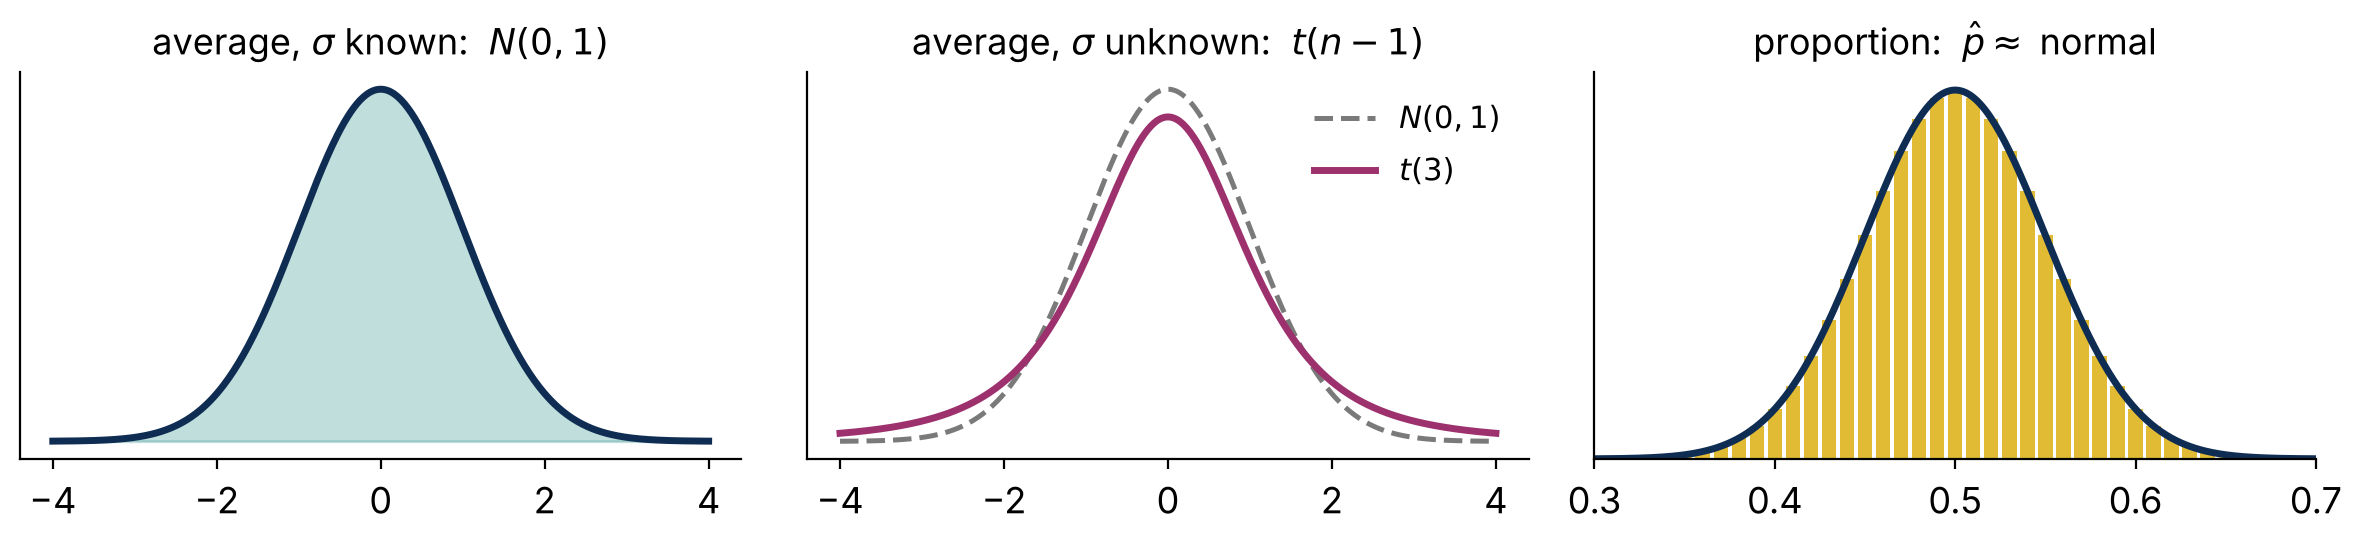

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 13, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUTDIR / name, dpi=200, facecolor="white", bbox_inches="tight")
    plt.show()

# Three reference curves: N(0,1), t vs N(0,1), and a binomial proportion with its normal approximation
x = np.linspace(-4, 4, 400)
fig, axes = plt.subplots(1, 3, figsize=(12, 2.9))

ax = axes[0]
ax.fill_between(x, stats.norm.pdf(x), color=TEAL, alpha=0.25)
ax.plot(x, stats.norm.pdf(x), color=NAVY, lw=2.5)
ax.set_title(r"average, $\sigma$ known:  $N(0,1)$", fontsize=13)

ax = axes[1]
ax.plot(x, stats.norm.pdf(x), color=GRAY, lw=1.8, ls="--", label=r"$N(0,1)$")
ax.plot(x, stats.t.pdf(x, 3), color=MAGENTA, lw=2.5, label=r"$t(3)$")
ax.legend(frameon=False, fontsize=11, loc="upper right")
ax.set_title(r"average, $\sigma$ unknown:  $t(n-1)$", fontsize=13)

ax = axes[2]
k = np.arange(30, 71)
ax.bar(k / 100, stats.binom.pmf(k, 100, 0.5) * 100, width=0.008, color=GOLD, alpha=0.8)
xx = np.linspace(0.3, 0.7, 300)
ax.plot(xx, stats.norm.pdf(xx, 0.5, 0.05), color=NAVY, lw=2.5)
ax.set_title(r"proportion:  $\hat p \approx$ normal", fontsize=13)
ax.set_xlim(0.3, 0.7)

for ax in axes:
    ax.set_yticks([])
save(fig, "three_tests.png")


## 1. Testing a mean ($t$-test): the coffee cart's claim

The company that sells these carts advertises that a cart averages **\$280 a day**. The new cart's first 10 days (Lecture 28):
269, 334, 341, 275, 269, 290, 320, 321, 293, 348. Test $H_0: \mu = 280$ against $H_1: \mu \ne 280$ at $\alpha = 0.05$.

$\sigma$ is unknown, so we use $s$ and the $t$ distribution with $n - 1 = 9$ degrees of freedom.

**Try it:** what if the company had claimed \$290? \$300?

n = 10, xbar = 306.00, s = 30.40, SE = 9.614
t* = 2.704, two-sided p-value = 0.0242  (exact, from the computer)
t_(9, 0.025) = 2.262;  95% CI = (284.25, 327.75)


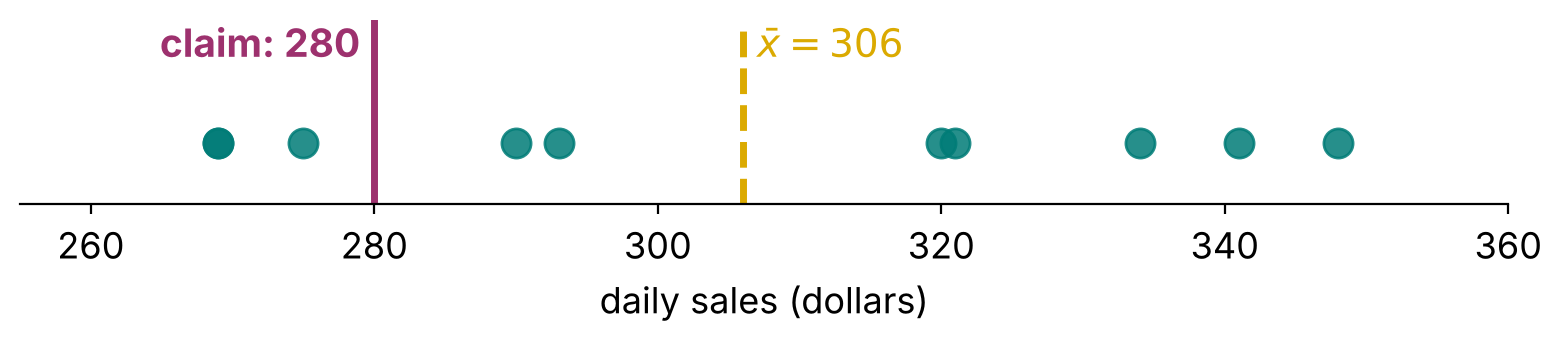

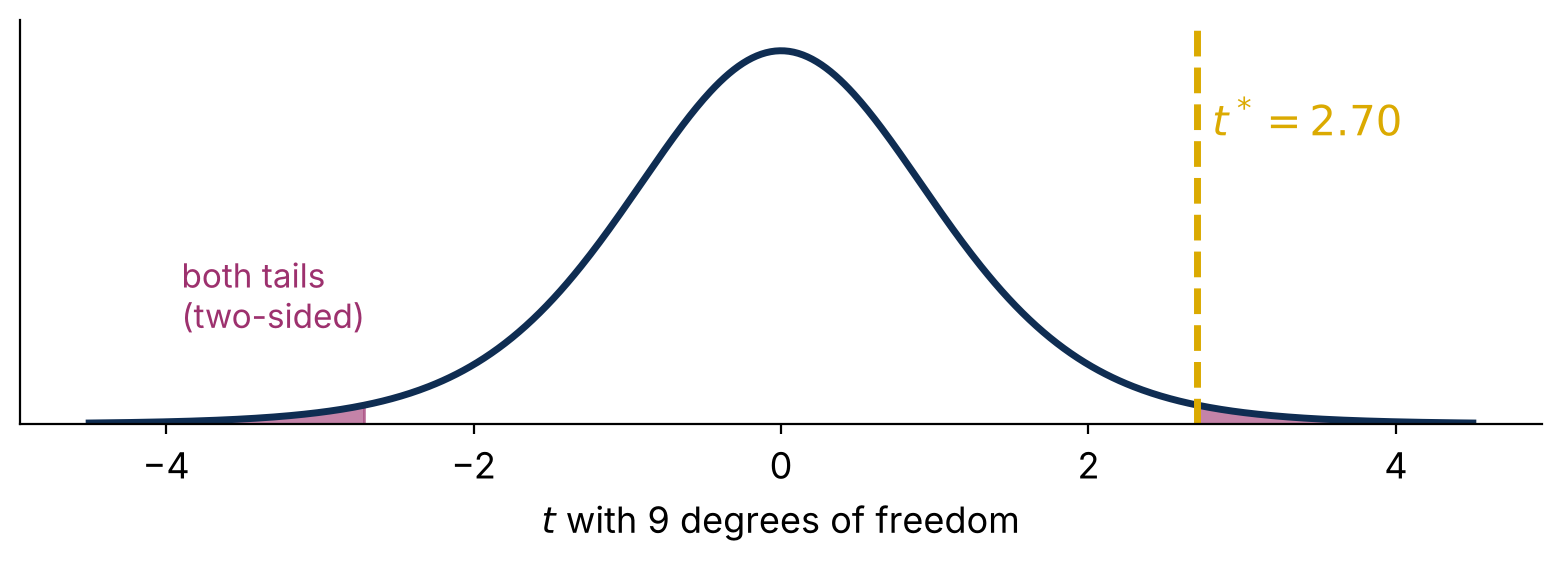

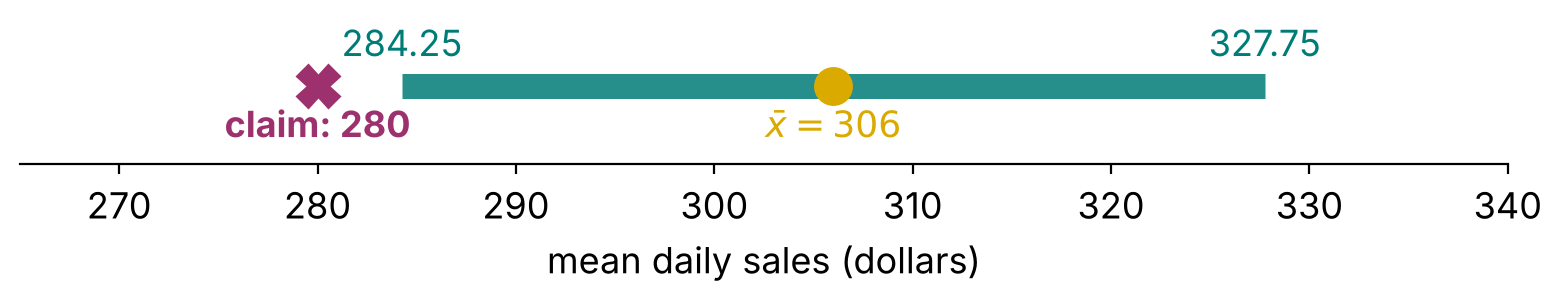

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 13, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUTDIR / name, dpi=200, facecolor="white", bbox_inches="tight")
    plt.show()

# Coffee cart: H0: mu = 280 vs H1: mu != 280,  sigma unknown -> t-test with 9 degrees of freedom
data = np.array([269, 334, 341, 275, 269, 290, 320, 321, 293, 348])
mu0, alpha = 280, 0.05
n = len(data); xbar = data.mean(); s = data.std(ddof=1)
se = s / np.sqrt(n)
t_star = (xbar - mu0) / se
p_two = 2 * stats.t.sf(abs(t_star), n - 1)
tcrit = stats.t.ppf(1 - alpha / 2, n - 1)
print(f"n = {n}, xbar = {xbar:.2f}, s = {s:.2f}, SE = {se:.3f}")
print(f"t* = {t_star:.3f}, two-sided p-value = {p_two:.4f}  (exact, from the computer)")
print(f"t_(9, 0.025) = {tcrit:.3f};  95% CI = ({xbar - tcrit*se:.2f}, {xbar + tcrit*se:.2f})")

# the data
fig, ax = plt.subplots(figsize=(8, 1.9))
ax.scatter(data, np.zeros(n), s=110, color=TEAL, zorder=3, alpha=0.85)
ax.axvline(xbar, color=GOLD, lw=2.5, ls="--")
ax.axvline(mu0, color=MAGENTA, lw=2.5)
ax.text(xbar + 1, 0.042, r"$\bar x = 306$", color=GOLD, fontsize=14, fontweight="bold")
ax.text(mu0 - 1, 0.042, "claim: 280", color=MAGENTA, fontsize=14, fontweight="bold", ha="right")
ax.set(xlim=(255, 360), ylim=(-0.03, 0.06), yticks=[], xlabel="daily sales (dollars)")
ax.spines["left"].set_visible(False)
save(fig, "cart_data.png")

# the p-value on the t(9) curve
x = np.linspace(-4.5, 4.5, 600)
f = stats.t.pdf(x, n - 1)
fig, ax = plt.subplots(figsize=(8, 3.0))
ax.plot(x, f, color=NAVY, lw=2.5)
ax.fill_between(x, f, where=x >= abs(t_star), color=MAGENTA, alpha=0.6)
ax.fill_between(x, f, where=x <= -abs(t_star), color=MAGENTA, alpha=0.6)
ax.axvline(t_star, color=GOLD, lw=2.5, ls="--")
ax.text(t_star + 0.1, 0.30, r"$t^* = 2.70$", color=GOLD, fontsize=15, fontweight="bold")
ax.text(-3.9, 0.10, "both tails\n(two-sided)", color=MAGENTA, fontsize=12)
ax.set(yticks=[], xlabel=r"$t$ with 9 degrees of freedom", ylim=(0, 0.42))
save(fig, "cart_pvalue.png")

# the matching 95% confidence interval
lo, hi = xbar - tcrit * se, xbar + tcrit * se
fig, ax = plt.subplots(figsize=(8, 1.7))
ax.plot([lo, hi], [0, 0], color=TEAL, lw=9, solid_capstyle="butt", alpha=0.85)
ax.plot(xbar, 0, "o", color=GOLD, ms=13, zorder=3)
ax.plot(mu0, 0, "X", color=MAGENTA, ms=15, zorder=3)
ax.text(lo, 0.5, f"{lo:.2f}", ha="center", fontsize=13, color=TEAL)
ax.text(hi, 0.5, f"{hi:.2f}", ha="center", fontsize=13, color=TEAL)
ax.text(mu0, -0.85, "claim: 280", ha="center", fontsize=13, color=MAGENTA, fontweight="bold")
ax.text(xbar, -0.85, r"$\bar x = 306$", ha="center", fontsize=13, color=GOLD, fontweight="bold")
ax.set(xlim=(265, 340), ylim=(-1.3, 1.1), yticks=[], xlabel="mean daily sales (dollars)")
ax.spines["left"].set_visible(False)
save(fig, "cart_ci.png")


## 2. Testing a proportion ($z$-test): is the coin fair?

You want to settle a bet with a coin toss, using your friend's coin. You flip it 100 times and get **61 heads**.
Test $H_0: p = 0.5$ against $H_1: p \ne 0.5$ at $\alpha = 0.05$.

For a test, the standard error uses the **claimed** value $p_0 = 0.5$; for the confidence interval it uses $\hat p = 0.61$.

**Try it:** what if you had flipped 200 times and gotten 122 heads (the same 61%)?

phat = 0.61, SE (p0) = 0.050, z* = 2.20, two-sided p-value = 0.0278
95% CI = (0.514, 0.706)
exact (binomial) two-sided p-value: 0.035200200217704855


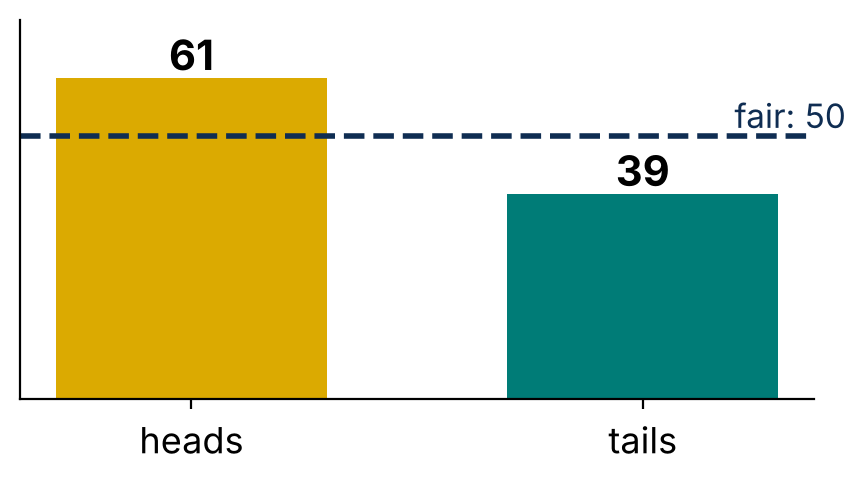

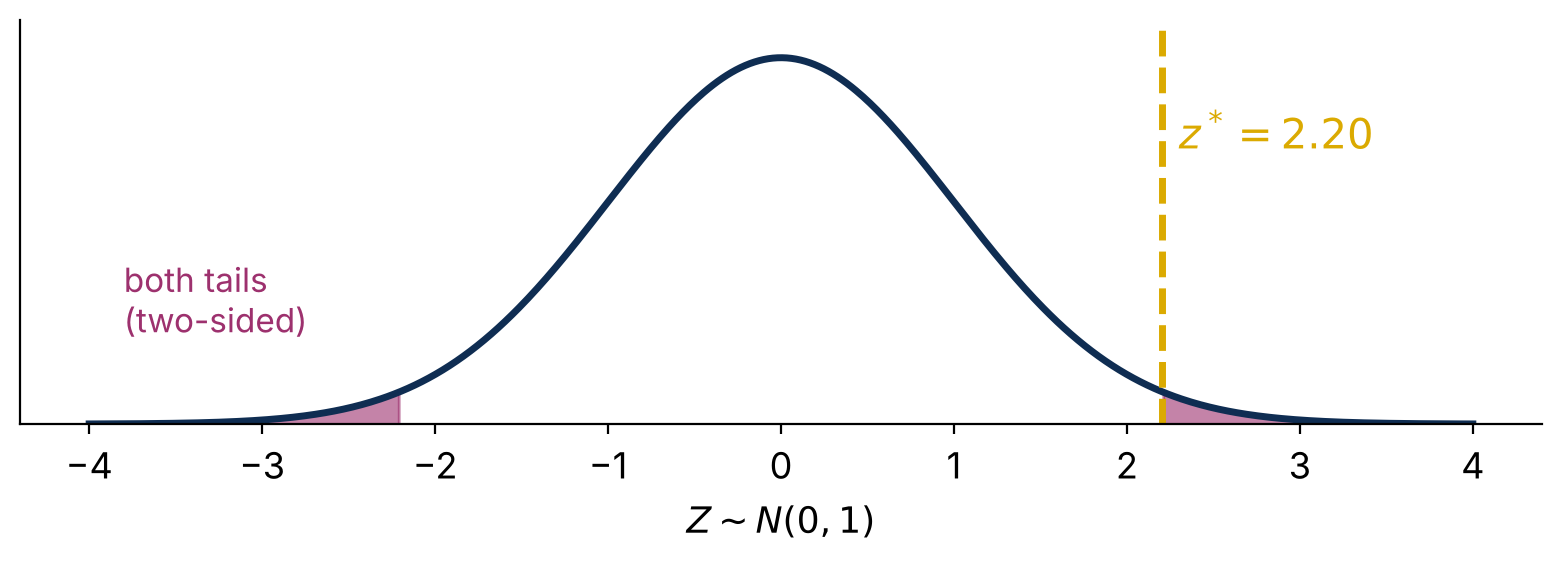

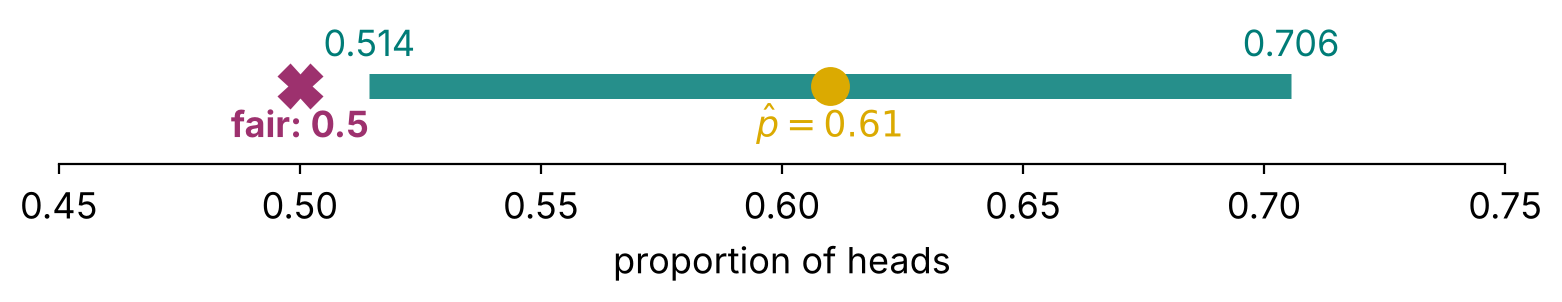

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 13, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUTDIR / name, dpi=200, facecolor="white", bbox_inches="tight")
    plt.show()

# Coin: H0: p = 0.5 vs H1: p != 0.5,  61 heads in 100 flips
p0, n, heads, alpha = 0.5, 100, 61, 0.05
phat = heads / n
se0 = np.sqrt(p0 * (1 - p0) / n)                    # test: SE uses p0
z_star = (phat - p0) / se0
p_two = 2 * stats.norm.sf(abs(z_star))
se_hat = np.sqrt(phat * (1 - phat) / n)             # confidence interval: SE uses phat
lo, hi = phat - 1.96 * se_hat, phat + 1.96 * se_hat
print(f"phat = {phat}, SE (p0) = {se0:.3f}, z* = {z_star:.2f}, two-sided p-value = {p_two:.4f}")
print(f"95% CI = ({lo:.3f}, {hi:.3f})")
print("exact (binomial) two-sided p-value:", 2 * stats.binom.sf(heads - 1, n, p0))

# the data
fig, ax = plt.subplots(figsize=(4.5, 2.6))
ax.bar(["heads", "tails"], [61, 39], color=[GOLD, TEAL], width=0.6)
ax.axhline(50, color=NAVY, ls="--", lw=2)
ax.text(1.45, 51.5, "fair: 50", color=NAVY, fontsize=12, ha="right")
for i, v in enumerate([61, 39]):
    ax.text(i, v + 1.5, str(v), ha="center", fontsize=15, fontweight="bold")
ax.set(ylim=(0, 72), yticks=[])
save(fig, "coin_data.png")

# the p-value on the N(0,1) curve
x = np.linspace(-4, 4, 600)
f = stats.norm.pdf(x)
fig, ax = plt.subplots(figsize=(8, 3.0))
ax.plot(x, f, color=NAVY, lw=2.5)
ax.fill_between(x, f, where=x >= abs(z_star), color=MAGENTA, alpha=0.6)
ax.fill_between(x, f, where=x <= -abs(z_star), color=MAGENTA, alpha=0.6)
ax.axvline(z_star, color=GOLD, lw=2.5, ls="--")
ax.text(z_star + 0.1, 0.30, r"$z^* = 2.20$", color=GOLD, fontsize=15, fontweight="bold")
ax.text(-3.8, 0.10, "both tails\n(two-sided)", color=MAGENTA, fontsize=12)
ax.set(yticks=[], xlabel=r"$Z \sim N(0,1)$", ylim=(0, 0.44))
save(fig, "coin_pvalue.png")

# the matching 95% confidence interval
fig, ax = plt.subplots(figsize=(8, 1.7))
ax.plot([lo, hi], [0, 0], color=TEAL, lw=9, solid_capstyle="butt", alpha=0.85)
ax.plot(phat, 0, "o", color=GOLD, ms=13, zorder=3)
ax.plot(p0, 0, "X", color=MAGENTA, ms=15, zorder=3)
ax.text(lo, 0.5, f"{lo:.3f}", ha="center", fontsize=13, color=TEAL)
ax.text(hi, 0.5, f"{hi:.3f}", ha="center", fontsize=13, color=TEAL)
ax.text(p0, -0.85, "fair: 0.5", ha="center", fontsize=13, color=MAGENTA, fontweight="bold")
ax.text(phat, -0.85, r"$\hat p = 0.61$", ha="center", fontsize=13, color=GOLD, fontweight="bold")
ax.set(xlim=(0.45, 0.75), ylim=(-1.3, 1.1), yticks=[], xlabel="proportion of heads")
ax.spines["left"].set_visible(False)
save(fig, "coin_ci.png")


## 3. Type I errors: $P(\text{Type I}) = \alpha$

We reject $H_0$ when the estimate falls past a **cutoff**. If $H_0$ is true, the chance of landing past a cutoff is exactly
the area we put there: $\alpha/2$ on each side, so $\alpha$ in total.

* Coffee cart: cutoffs $280 \pm t_{9,0.025}\cdot \frac{s}{\sqrt n} = 280 \pm 21.75$.
* Coin: cutoffs $0.5 \pm 1.96 \cdot 0.05 = 0.5 \pm 0.098$.

The simulation checks it: when $H_0$ is true, about 5% of studies reject. (For the coin it's a bit over 5%, because heads come in whole numbers.)

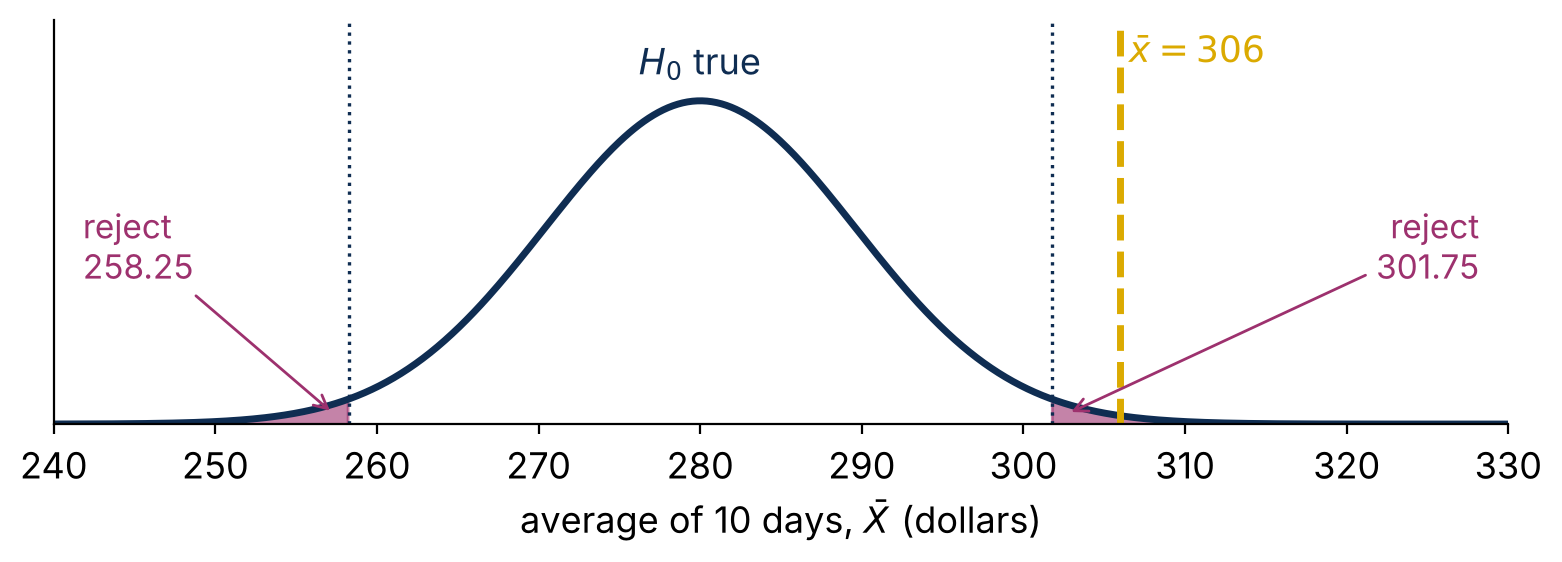

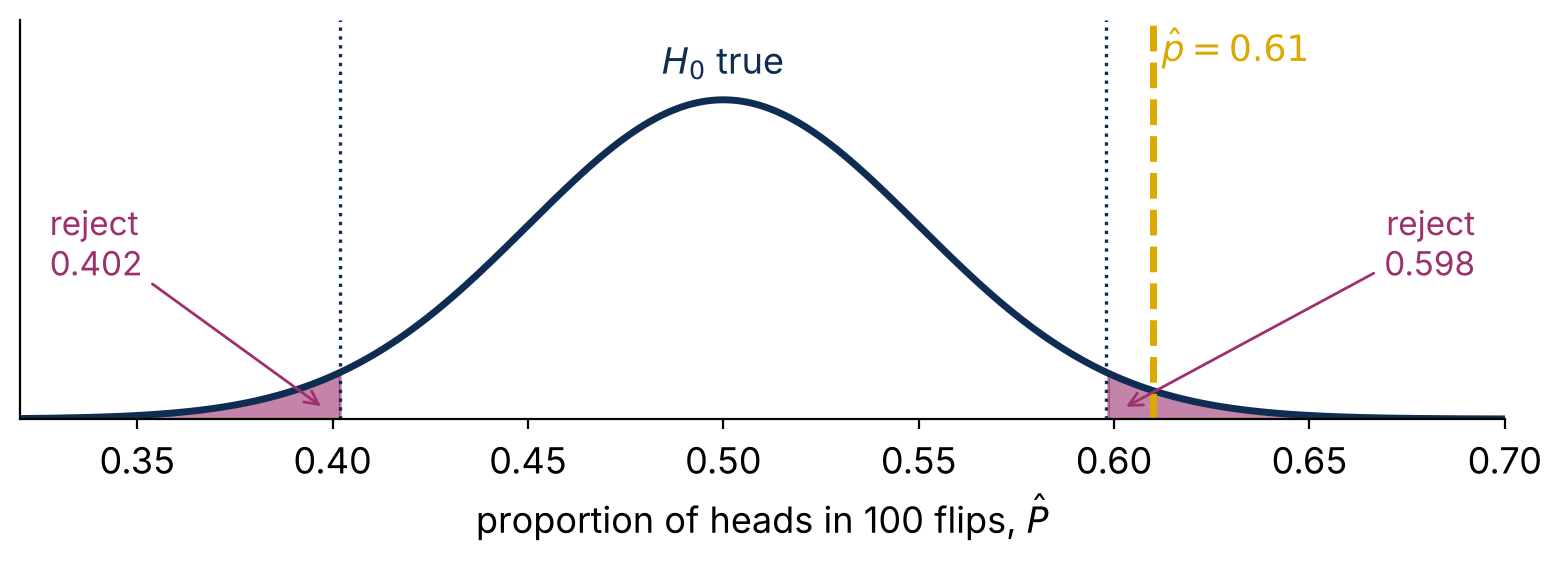

fair coin rejected (Type I error) in 0.057495 of studies


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 13, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUTDIR / name, dpi=200, facecolor="white", bbox_inches="tight")
    plt.show()

# Type I error = alpha.  Draw the H0 picture with the cutoffs, and check by simulation.
def h0_picture(center, se, lo, hi, est, est_label, xlabel, xlim, name, ticks_fmt):
    x = np.linspace(*xlim, 600)
    f = stats.norm.pdf(x, center, se)
    fig, ax = plt.subplots(figsize=(8, 3.0))
    ax.plot(x, f, color=NAVY, lw=2.5)
    ax.fill_between(x, f, where=x <= lo, color=MAGENTA, alpha=0.6)
    ax.fill_between(x, f, where=x >= hi, color=MAGENTA, alpha=0.6)
    for c in (lo, hi):
        ax.axvline(c, color=NAVY, lw=1.2, ls=":")
    top = f.max()
    ax.text(center, top * 1.08, r"$H_0$ true", ha="center", fontsize=13, color=NAVY)
    span = xlim[1] - xlim[0]
    ax.annotate("reject\n" + ticks_fmt.format(lo), xy=(lo - 0.01 * span, top * 0.03), xytext=(xlim[0] + 0.02 * span, top * 0.45),
                fontsize=12, color=MAGENTA, ha="left", arrowprops=dict(arrowstyle="->", color=MAGENTA))
    ax.annotate("reject\n" + ticks_fmt.format(hi), xy=(hi + 0.01 * span, top * 0.03), xytext=(xlim[1] - 0.02 * span, top * 0.45),
                fontsize=12, color=MAGENTA, ha="right", arrowprops=dict(arrowstyle="->", color=MAGENTA))
    ax.axvline(est, color=GOLD, lw=2.5, ls="--")
    ax.text(est, top * 1.12, est_label, color=GOLD, fontsize=13, fontweight="bold", ha="left")
    ax.set(yticks=[], xlabel=xlabel, xlim=xlim, ylim=(0, top * 1.25))
    save(fig, name)

# coffee cart (normal picture of xbar, using s/sqrt(n) as the standard error)
se = 30.40 / np.sqrt(10); m = stats.t.ppf(0.975, 9) * se
h0_picture(280, se, 280 - m, 280 + m, 306, r" $\bar x = 306$", r"average of 10 days, $\bar X$ (dollars)",
           (240, 330), "cart_typeI.png", "{:.2f}")

# coin
h0_picture(0.5, 0.05, 0.402, 0.598, 0.61, r" $\hat p = 0.61$", r"proportion of heads in 100 flips, $\hat P$",
           (0.32, 0.70), "coin_typeI.png", "{:.3f}")

# simulation: a FAIR coin, 100 flips, 200,000 times. How often do we (wrongly) reject?
rng = np.random.default_rng(31)
heads = rng.binomial(100, 0.5, size=200_000)
z = (heads / 100 - 0.5) / 0.05
print("fair coin rejected (Type I error) in", np.mean(np.abs(z) >= 1.96), "of studies")


## 4. Type II errors: $\beta$ = P(fail to reject $H_0$ | $H_0$ is false)

**Recipe.** (1) Find the cutoffs from $H_0$. (2) Pick the **true** value. (3) $\beta$ = area under the **true** curve
*between* the cutoffs (where we don't reject).

* Coffee cart: behind the curtain (Lecture 28), the true mean is \$300. (For $\beta$ we use the normal curve with $s$ in place of $\sigma$: an approximation.)
* Coin: suppose the coin really lands heads 60% of the time. Compare 100 flips with 400 flips.

**Try it:** change `p_true` to 0.55 or 0.7. Change `n` to 1000.

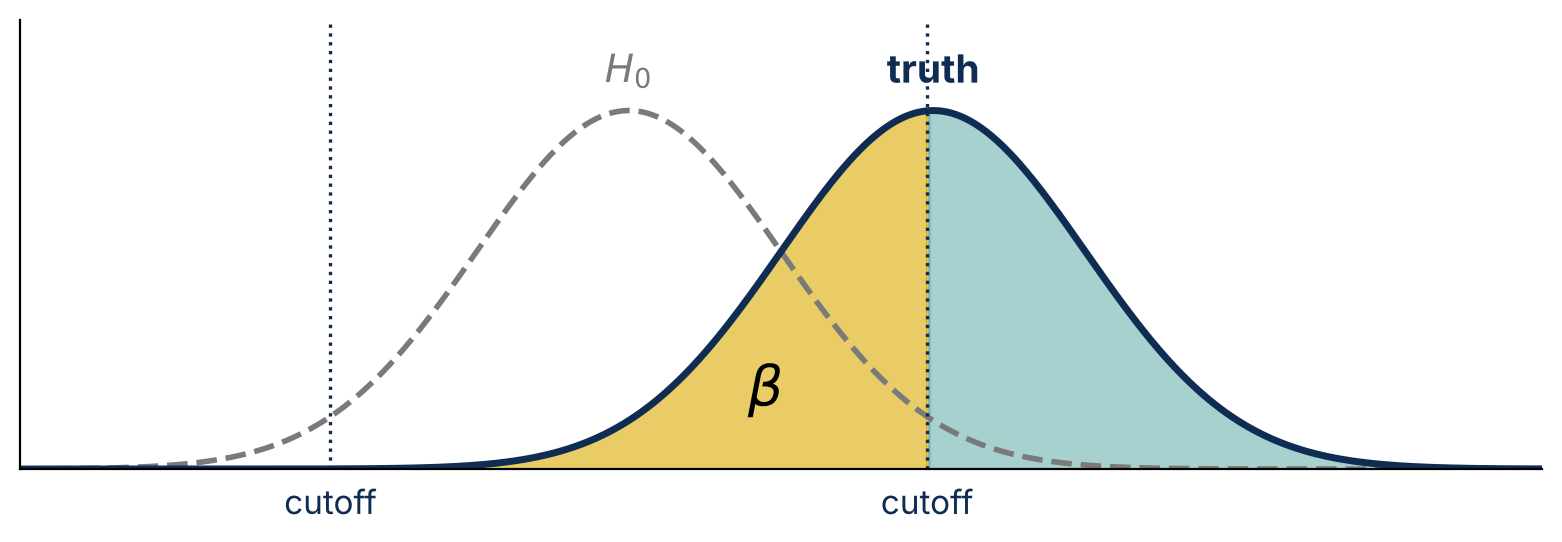

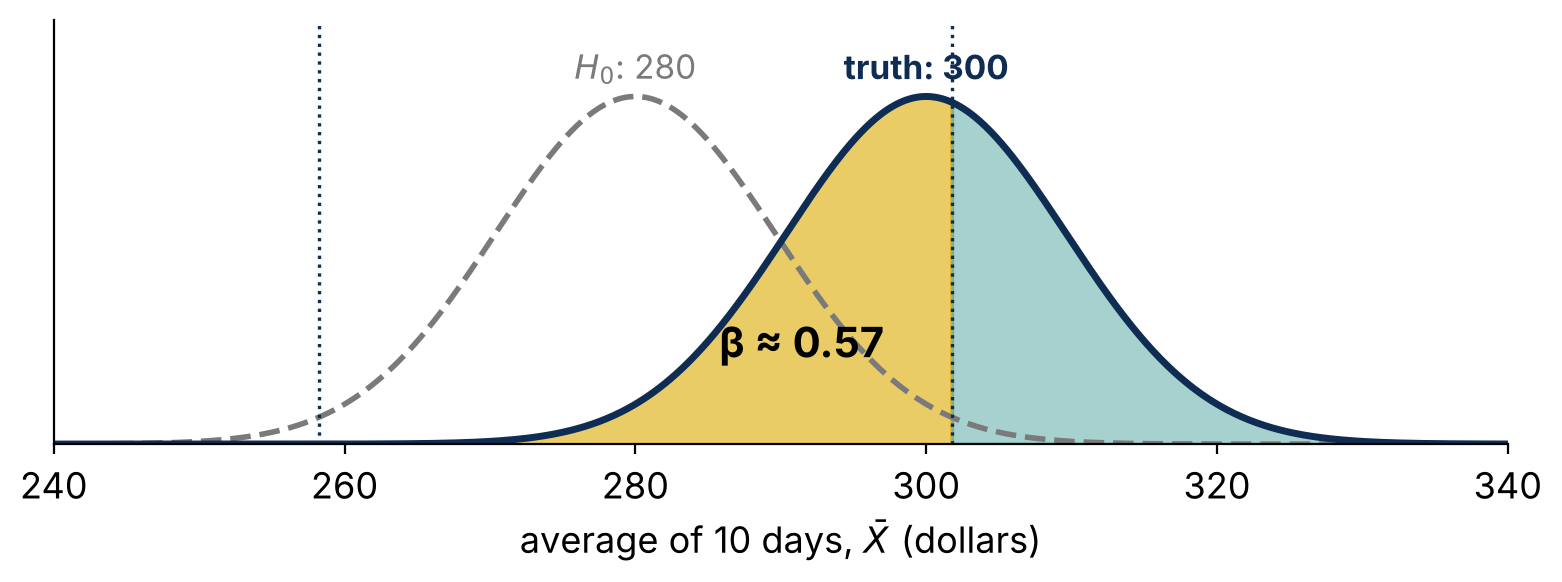

coffee cart: cutoffs (258.25, 301.75),  beta = 0.572


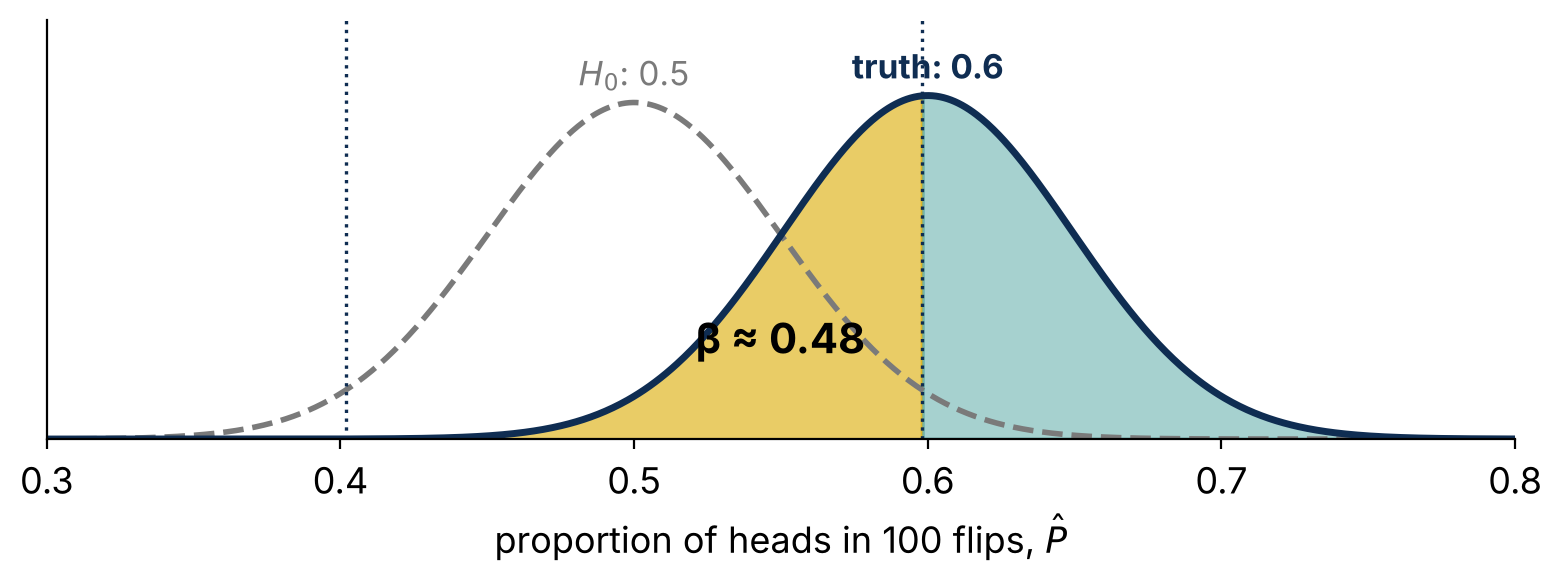

coin, n = 100: cutoffs (0.402, 0.598),  beta (normal) = 0.484,  beta (exact binomial) = 0.457


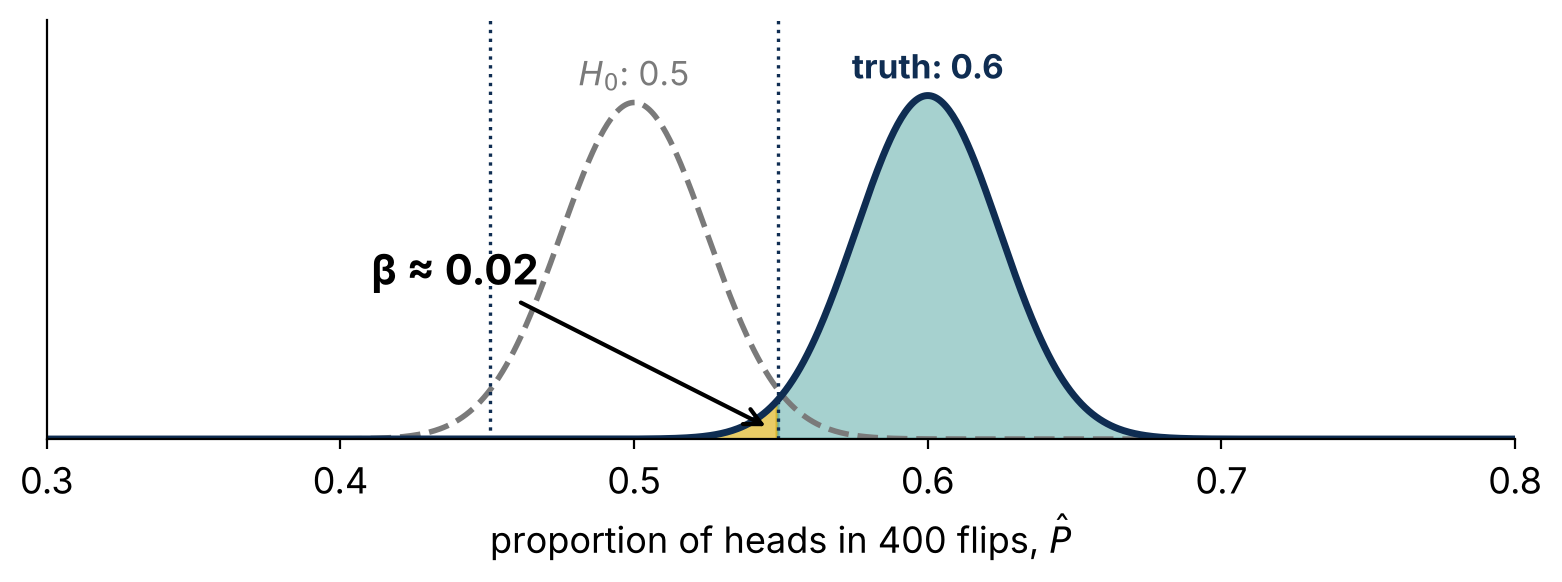

coin, n = 400: cutoffs (0.451, 0.549),  beta (normal) = 0.019,  beta (exact binomial) = 0.019


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 13, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUTDIR / name, dpi=200, facecolor="white", bbox_inches="tight")
    plt.show()

# Type II error: area under the TRUE curve between the cutoffs
def beta_picture(c0, se0, lo, hi, c1, se1, xlabel, xlim, name, label0, label1):
    x = np.linspace(*xlim, 800)
    f0 = stats.norm.pdf(x, c0, se0)
    f1 = stats.norm.pdf(x, c1, se1)
    beta = stats.norm.cdf(hi, c1, se1) - stats.norm.cdf(lo, c1, se1)
    fig, ax = plt.subplots(figsize=(8, 3.1))
    ax.plot(x, f0, color=GRAY, lw=2, ls="--")
    ax.plot(x, f1, color=NAVY, lw=2.5)
    ax.fill_between(x, f1, where=(x > lo) & (x < hi), color=GOLD, alpha=0.6)
    ax.fill_between(x, f1, where=(x >= hi) | (x <= lo), color=TEAL, alpha=0.35)
    for c in (lo, hi):
        ax.axvline(c, color=NAVY, lw=1.2, ls=":")
    top = max(f0.max(), f1.max())
    ax.text(c0, f0.max() * 1.05, label0, ha="center", fontsize=12, color=GRAY)
    ax.text(c1, f1.max() * 1.05, label1, ha="center", fontsize=12, color=NAVY, fontweight="bold")
    if beta > 0.1:
        xb = hi - 0.4 * (hi - max(lo, c1 - 2.5 * se1))
        ax.text(xb, f1.max() * 0.25, f"β ≈ {beta:.2f}", ha="center", fontsize=15, color="black", fontweight="bold")
    else:
        span = xlim[1] - xlim[0]
        ax.annotate(f"β ≈ {beta:.2f}", xy=(hi - 0.005 * span, f1.max() * 0.03), xytext=(hi - 0.22 * span, f1.max() * 0.45),
                    fontsize=15, fontweight="bold", ha="center", arrowprops=dict(arrowstyle="->", color="black", lw=1.5))
    ax.set(yticks=[], xlabel=xlabel, xlim=xlim, ylim=(0, top * 1.22))
    save(fig, name)
    return beta

# a generic picture for the recipe slide
x = np.linspace(-4, 6, 800)
f0, f1 = stats.norm.pdf(x, 0, 1), stats.norm.pdf(x, 2, 1)
fig, ax = plt.subplots(figsize=(8, 2.9))
ax.plot(x, f0, color=GRAY, lw=2, ls="--"); ax.plot(x, f1, color=NAVY, lw=2.5)
ax.fill_between(x, f1, where=(x > -1.96) & (x < 1.96), color=GOLD, alpha=0.6)
ax.fill_between(x, f1, where=(x >= 1.96), color=TEAL, alpha=0.35)
for c in (-1.96, 1.96):
    ax.axvline(c, color=NAVY, lw=1.2, ls=":")
ax.text(0, 0.43, r"$H_0$", ha="center", fontsize=14, color=GRAY)
ax.text(2, 0.43, "truth", ha="center", fontsize=14, color=NAVY, fontweight="bold")
ax.text(0.9, 0.07, r"$\beta$", ha="center", fontsize=20, fontweight="bold")
ax.text(-1.96, -0.05, "cutoff", ha="center", fontsize=12, color=NAVY)
ax.text(1.96, -0.05, "cutoff", ha="center", fontsize=12, color=NAVY)
ax.set(xticks=[], yticks=[], xlim=(-4, 6), ylim=(0, 0.5))
save(fig, "typeII_generic.png")

# coffee cart: H0 says 280, the truth is 300
se = 30.40 / np.sqrt(10); m = stats.t.ppf(0.975, 9) * se
b = beta_picture(280, se, 280 - m, 280 + m, 300, se, r"average of 10 days, $\bar X$ (dollars)", (240, 340),
                 "cart_typeII.png", r"$H_0$: 280", r"truth: 300")
print(f"coffee cart: cutoffs ({280-m:.2f}, {280+m:.2f}),  beta = {b:.3f}")

# coin: H0 says 0.5, the truth is 0.6
p_true = 0.6
for n, name in [(100, "coin_typeII_100.png"), (400, "coin_typeII_400.png")]:
    se0 = np.sqrt(0.25 / n); lo, hi = 0.5 - 1.96 * se0, 0.5 + 1.96 * se0
    se1 = np.sqrt(p_true * (1 - p_true) / n)
    b = beta_picture(0.5, se0, lo, hi, p_true, se1, rf"proportion of heads in {n} flips, $\hat P$", (0.3, 0.8),
                     name, r"$H_0$: 0.5", rf"truth: {p_true}")
    # exact check with the binomial: we fail to reject when the count is strictly between the cutoffs
    k = np.arange(n + 1); keep = (k / n > lo) & (k / n < hi)
    print(f"coin, n = {n}: cutoffs ({lo:.3f}, {hi:.3f}),  beta (normal) = {b:.3f},  "
          f"beta (exact binomial) = {stats.binom.pmf(k[keep], n, p_true).sum():.3f}")
